# FRB Data Augmentation Pipeline v5

**Fixes from v4:**
- Native time resolution is 2.56 μs — way too fine for detection
- Time-downsample to ~1 ms first (standard for FRB search pipelines)
- Then redisperse with correct effective time resolution
- Crop to live frequency channels

**Pipeline per file:**
1. Load dedispersed beamformed data (2.56 μs native)
2. Downsample time axis by factor ~384 → ~1 ms resolution
3. Crop to live frequency channels
4. Re-disperse at target DM → diagonal sweep
5. Extract (256 time, 256 freq) patch, normalize

**Output:** `(batch, 256, 256)` LSTM-ready — each patch covers ~252 ms

In [1]:
import numpy as np
import h5py
import os
import glob
import json
import matplotlib.pyplot as plt
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

FRB_H5_DIR    = "./realtime_data/FRBs/"
DM_CATALOG    = "./dm_catalog.json"
OUTPUT_DIR    = "./augmented_dataset/"
os.makedirs(OUTPUT_DIR, exist_ok=True)

with open(DM_CATALOG, 'r') as f:
    dm_catalog = json.load(f)

print(f"DM catalog: {len(dm_catalog)} files")
print(f"DM range: {min(v['dm'] for v in dm_catalog.values()):.1f} – "
      f"{max(v['dm'] for v in dm_catalog.values()):.1f} pc/cm³")

DM catalog: 30 files
DM range: 187.5 – 2002.4 pc/cm³


In [2]:
# ============================================================
# CONFIGURATION
# ============================================================

# Physics
CHIME_FREQ_LOW   = 400.0       # MHz
CHIME_FREQ_HIGH  = 800.0       # MHz
NATIVE_TIME_RES  = 2.56e-6     # seconds (2.56 μs — from file attrs delta_time)
K_DM             = 4.148808e3  # MHz^2 pc^-1 cm^3 s

# Time downsampling
TIME_DOWNSAMPLE  = 256
EFFECTIVE_TIME_RES = NATIVE_TIME_RES * TIME_DOWNSAMPLE  # ~0.000983 s

# Patch dimensions
PATCH_TIME_BINS  = 256         # LSTM sequence length (~252 ms at effective resolution)
TARGET_FREQ_BINS = 256         # LSTM feature dimension

# Augmentation
N_DM_AUGMENTS    = 30
DM_AUG_RANGE     = (100, 2500)
N_TEMPORAL_SHIFTS = 8
BURST_EXCLUSION_FACTOR = 3.0

# Quality
MIN_BURST_SNR    = 3.0
NAN_THRESHOLD    = 0.3
LIVE_CHANNEL_THRESHOLD = 0.5

SEED = 42
rng = np.random.RandomState(SEED)

print(f"Native time resolution:    {NATIVE_TIME_RES*1e6:.2f} μs")
print(f"Downsample factor:         {TIME_DOWNSAMPLE}")
print(f"Effective time resolution: {EFFECTIVE_TIME_RES*1000:.3f} ms")
print(f"Patch duration:            {PATCH_TIME_BINS * EFFECTIVE_TIME_RES * 1000:.1f} ms")
print(f"\nDispersive delays at effective resolution:")
for dm in [100, 300, 500, 1000, 2000]:
    delay_s = K_DM * dm * (CHIME_FREQ_LOW**-2 - CHIME_FREQ_HIGH**-2)
    delay_bins = int(np.round(delay_s / EFFECTIVE_TIME_RES))
    print(f"  DM={dm:>5.0f}: {delay_s*1000:>8.1f} ms = {delay_bins:>6d} bins "
          f"{'✅ fits in patch' if delay_bins < PATCH_TIME_BINS else '⚠️  partial sweep in patch'}")

Native time resolution:    2.56 μs
Downsample factor:         256
Effective time resolution: 0.655 ms
Patch duration:            167.8 ms

Dispersive delays at effective resolution:
  DM=  100:   1944.8 ms =   2967 bins ⚠️  partial sweep in patch
  DM=  300:   5834.3 ms =   8902 bins ⚠️  partial sweep in patch
  DM=  500:   9723.8 ms =  14837 bins ⚠️  partial sweep in patch
  DM= 1000:  19447.5 ms =  29675 bins ⚠️  partial sweep in patch
  DM= 2000:  38895.1 ms =  59349 bins ⚠️  partial sweep in patch


## 1. Load, Downsample & Discover Live Channels

In [3]:
def load_spectrogram(fpath, power_key, beam_idx=0):
    """Load H5 data as (n_time, n_freq)."""
    with h5py.File(fpath, 'r') as f:
        ds = f[power_key]
        if ds.ndim == 3:
            power = ds[:, beam_idx, :].T  # (freq, beam, time) → (time, freq)
        elif ds.ndim == 2:
            power = ds[()]
            if power.shape[1] > power.shape[0]:
                power = power.T
        else:
            raise ValueError(f"Unexpected ndim={ds.ndim}")
    return power.astype(np.float32)


def downsample_time(power_2d, factor):
    """
    Downsample time axis by averaging consecutive bins.
    Truncates to a multiple of `factor` before reshaping.
    
    (n_time, n_freq) → (n_time // factor, n_freq)
    """
    n_time, n_freq = power_2d.shape
    n_trim = (n_time // factor) * factor
    trimmed = power_2d[:n_trim, :]
    reshaped = trimmed.reshape(n_trim // factor, factor, n_freq)
    return np.nanmean(reshaped, axis=1)


def find_live_channels(power_2d, threshold=LIVE_CHANNEL_THRESHOLD):
    """Identify frequency channels with real (non-zero, varying) data."""
    n_time, n_freq = power_2d.shape
    live_mask = np.zeros(n_freq, dtype=bool)
    for ch in range(n_freq):
        col = power_2d[:, ch]
        valid = ~np.isnan(col) & (col != 0)
        if np.mean(valid) > threshold and np.nanstd(col[valid]) > 0:
            live_mask[ch] = True
    return live_mask, np.where(live_mask)[0]


def crop_to_live_channels(power_2d, live_indices):
    return power_2d[:, live_indices]

print("Load functions ready.")

Load functions ready.


In [4]:
# Load all files: load → downsample time → find live channels
file_info = {}
skipped = []

for fname, cat in dm_catalog.items():
    fpath = os.path.join(FRB_H5_DIR, fname)
    if not os.path.exists(fpath):
        print(f"⚠️  Missing: {fname}")
        skipped.append(fname)
        continue
    
    try:
        # Find power key
        with h5py.File(fpath, 'r') as f:
            power_key = None
            for candidate in ["tiedbeam_power", "intensity", "data",
                              "beamformed_data", "beam_power"]:
                if candidate in f:
                    power_key = candidate
                    break
            if power_key is None:
                max_size = 0
                for key in f.keys():
                    if isinstance(f[key], h5py.Dataset) and f[key].size > max_size:
                        max_size = f[key].size
                        power_key = key
            raw_shape = f[power_key].shape
        
        # Load and downsample
        power_raw = load_spectrogram(fpath, power_key)
        power_ds = downsample_time(power_raw, TIME_DOWNSAMPLE)
        
        # Find live channels on downsampled data
        live_mask, live_idx = find_live_channels(power_ds)
        
        file_info[fname] = {
            "path": fpath,
            "dm": cat["dm"],
            "power_key": power_key,
            "raw_shape": power_raw.shape,
            "ds_shape": power_ds.shape,
            "n_live_channels": len(live_idx),
            "live_indices": live_idx,
        }
        
    except OSError as e:
        print(f"❌ Corrupted: {fname}")
        skipped.append(fname)

print(f"\nLoaded: {len(file_info)}/{len(dm_catalog)} files")
print(f"\n{'Filename':<55} {'Raw':<18} {'Downsampled':<16} {'Live Ch':>8} {'DM':>8}")
print("-" * 112)
for fname, info in file_info.items():
    print(f"{fname:<55} {str(info['raw_shape']):<18} {str(info['ds_shape']):<16} "
          f"{info['n_live_channels']:>8} {info['dm']:>8.1f}")


Loaded: 30/30 files

Filename                                                Raw                Downsampled       Live Ch       DM
----------------------------------------------------------------------------------------------------------------
FRB20181209A_22154974_beamformed.h5                     (75913, 903)       (296, 903)            903    328.6
FRB20181213A_22310619_beamformed.h5                     (75913, 895)       (296, 895)            895    678.7
FRB20181226E_23948798_beamformed.h5                     (84167, 348)       (328, 348)            298    308.9
FRB20181231A_24342210_beamformed.h5                     (93215, 446)       (364, 446)            405   1376.8
FRB20181231C_24366209_beamformed.h5                     (57490, 108)       (224, 108)            102    556.2
FRB20190102A_24510924_beamformed.h5                     (66728, 168)       (260, 168)            162    699.2
FRB20190103C_24644651_beamformed.h5                     (126466, 317)      (494, 317)          

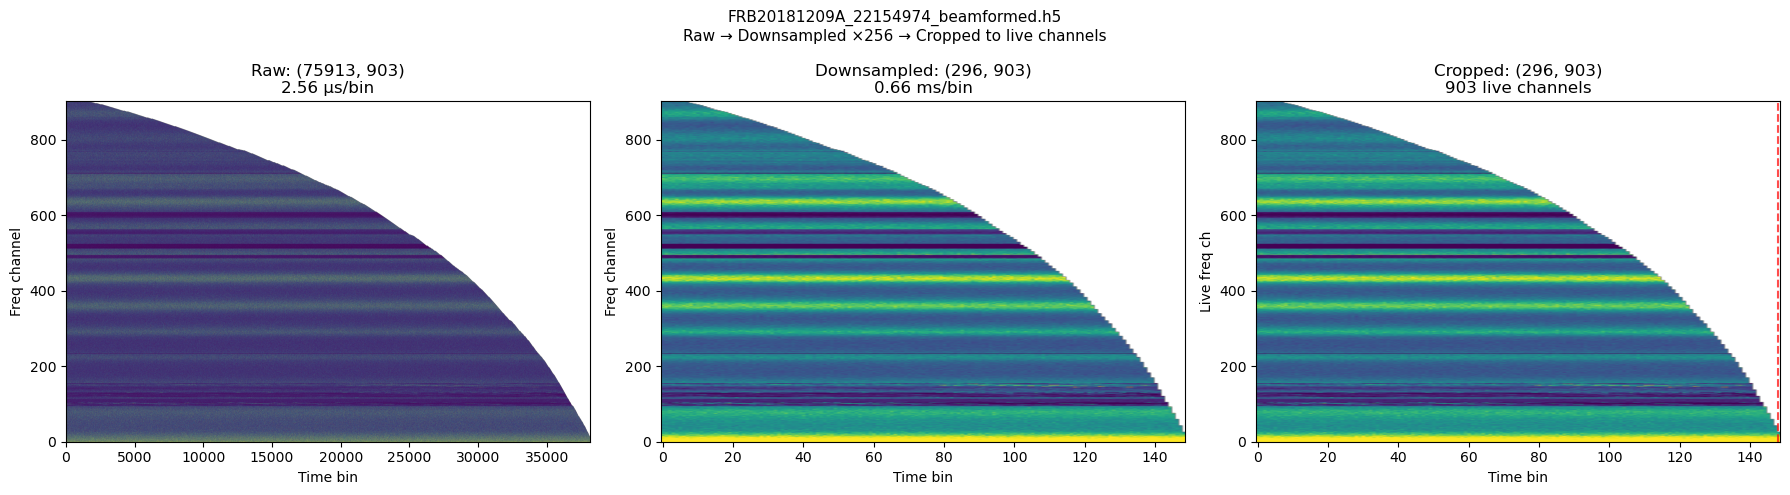


Raw:         75913 bins × 2.6 μs = 194.3 ms
Downsampled: 296 bins × 0.655 ms = 194.0 ms
Live channels: 903 / 903


In [5]:
# Visualize: raw vs downsampled vs cropped for first file
demo_fname = list(file_info.keys())[0]
demo_info = file_info[demo_fname]

demo_raw = load_spectrogram(demo_info["path"], demo_info["power_key"])
demo_ds = downsample_time(demo_raw, TIME_DOWNSAMPLE)
demo_cropped = crop_to_live_channels(demo_ds, demo_info["live_indices"])

# Find burst in downsampled+cropped
ts = np.nanmean(demo_cropped, axis=1)
peak = np.nanargmax(ts - np.nanmedian(ts))
margin = min(200, demo_cropped.shape[0] // 2)
t_lo = max(0, peak - margin)
t_hi = min(demo_cropped.shape[0], peak + margin)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Raw (native resolution)
raw_t_lo = t_lo * TIME_DOWNSAMPLE
raw_t_hi = t_hi * TIME_DOWNSAMPLE
raw_win = demo_raw[raw_t_lo:raw_t_hi, :]
v1, v2 = np.nanpercentile(raw_win, [2, 98])
axes[0].imshow(raw_win.T, aspect='auto', origin='lower', vmin=v1, vmax=v2, cmap='viridis')
axes[0].set_title(f"Raw: {demo_raw.shape}\n2.56 μs/bin")
axes[0].set_ylabel("Freq channel")

# Downsampled (all channels)
ds_win = demo_ds[t_lo:t_hi, :]
v1, v2 = np.nanpercentile(ds_win, [2, 98])
axes[1].imshow(ds_win.T, aspect='auto', origin='lower', vmin=v1, vmax=v2, cmap='viridis')
axes[1].set_title(f"Downsampled: {demo_ds.shape}\n{EFFECTIVE_TIME_RES*1000:.2f} ms/bin")
axes[1].set_ylabel("Freq channel")

# Cropped (live channels only)
crop_win = demo_cropped[t_lo:t_hi, :]
v1, v2 = np.nanpercentile(crop_win, [2, 98])
axes[2].imshow(crop_win.T, aspect='auto', origin='lower', vmin=v1, vmax=v2, cmap='viridis')
axes[2].set_title(f"Cropped: {demo_cropped.shape}\n{demo_info['n_live_channels']} live channels")
axes[2].set_ylabel("Live freq ch")
axes[2].axvline(peak - t_lo, color='r', ls='--', alpha=0.7)

for ax in axes:
    ax.set_xlabel("Time bin")

plt.suptitle(f"{demo_fname}\nRaw → Downsampled ×{TIME_DOWNSAMPLE} → Cropped to live channels", fontsize=11)
plt.tight_layout()
plt.show()

print(f"\nRaw:         {demo_raw.shape[0]} bins × {NATIVE_TIME_RES*1e6:.1f} μs = "
      f"{demo_raw.shape[0] * NATIVE_TIME_RES * 1000:.1f} ms")
print(f"Downsampled: {demo_ds.shape[0]} bins × {EFFECTIVE_TIME_RES*1000:.3f} ms = "
      f"{demo_ds.shape[0] * EFFECTIVE_TIME_RES * 1000:.1f} ms")
print(f"Live channels: {demo_info['n_live_channels']} / {demo_ds.shape[1]}")

## 2. Core Functions

In [6]:
def compute_delay_bins(dm, freq_lo=CHIME_FREQ_LOW, freq_hi=CHIME_FREQ_HIGH,
                       time_res=EFFECTIVE_TIME_RES):
    """Dispersive delay in DOWNSAMPLED time bins."""
    dt = K_DM * dm * (freq_lo**-2 - freq_hi**-2)
    return int(np.round(dt / time_res))


def redisperse(power_2d, dm, freq_lo=CHIME_FREQ_LOW, freq_hi=CHIME_FREQ_HIGH,
               time_res=EFFECTIVE_TIME_RES):
    """
    Apply dispersive delay to a dedispersed, downsampled, cropped spectrogram.
    Uses EFFECTIVE_TIME_RES (post-downsampling).
    """
    n_time, n_freq = power_2d.shape
    freqs = np.linspace(freq_hi, freq_lo, n_freq)
    delays = np.round(K_DM * dm * (freqs**-2 - freq_hi**-2) / time_res).astype(int)
    
    rd = np.full_like(power_2d, np.nan)
    for i in range(n_freq):
        s = delays[i]
        if s == 0:
            rd[:, i] = power_2d[:, i]
        elif s < n_time:
            rd[s:, i] = power_2d[:n_time - s, i]
    return rd


def resample_freq(power_2d, target_bins):
    """Resample frequency axis."""
    n_time, n_freq = power_2d.shape
    if n_freq == target_bins:
        return power_2d
    if n_freq > target_bins:
        edges = np.linspace(0, n_freq, target_bins + 1, dtype=int)
        out = np.zeros((n_time, target_bins), dtype=np.float32)
        for i in range(target_bins):
            out[:, i] = np.nanmean(power_2d[:, edges[i]:edges[i+1]], axis=1)
        return out
    else:
        from scipy.interpolate import interp1d
        x_old = np.linspace(0, 1, n_freq)
        x_new = np.linspace(0, 1, target_bins)
        return interp1d(x_old, power_2d, axis=1, kind='linear',
                        fill_value='extrapolate')(x_new).astype(np.float32)


def normalize_patch(patch):
    mean = np.nanmean(patch)
    std = np.nanstd(patch)
    return (patch - mean) / std if std > 0 else patch - mean


def patch_is_valid(patch, nan_threshold=NAN_THRESHOLD):
    if np.mean(np.isnan(patch)) > nan_threshold:
        return False
    if np.nanstd(patch) < 1e-10:
        return False
    return True

print("Core functions ready.")

Core functions ready.


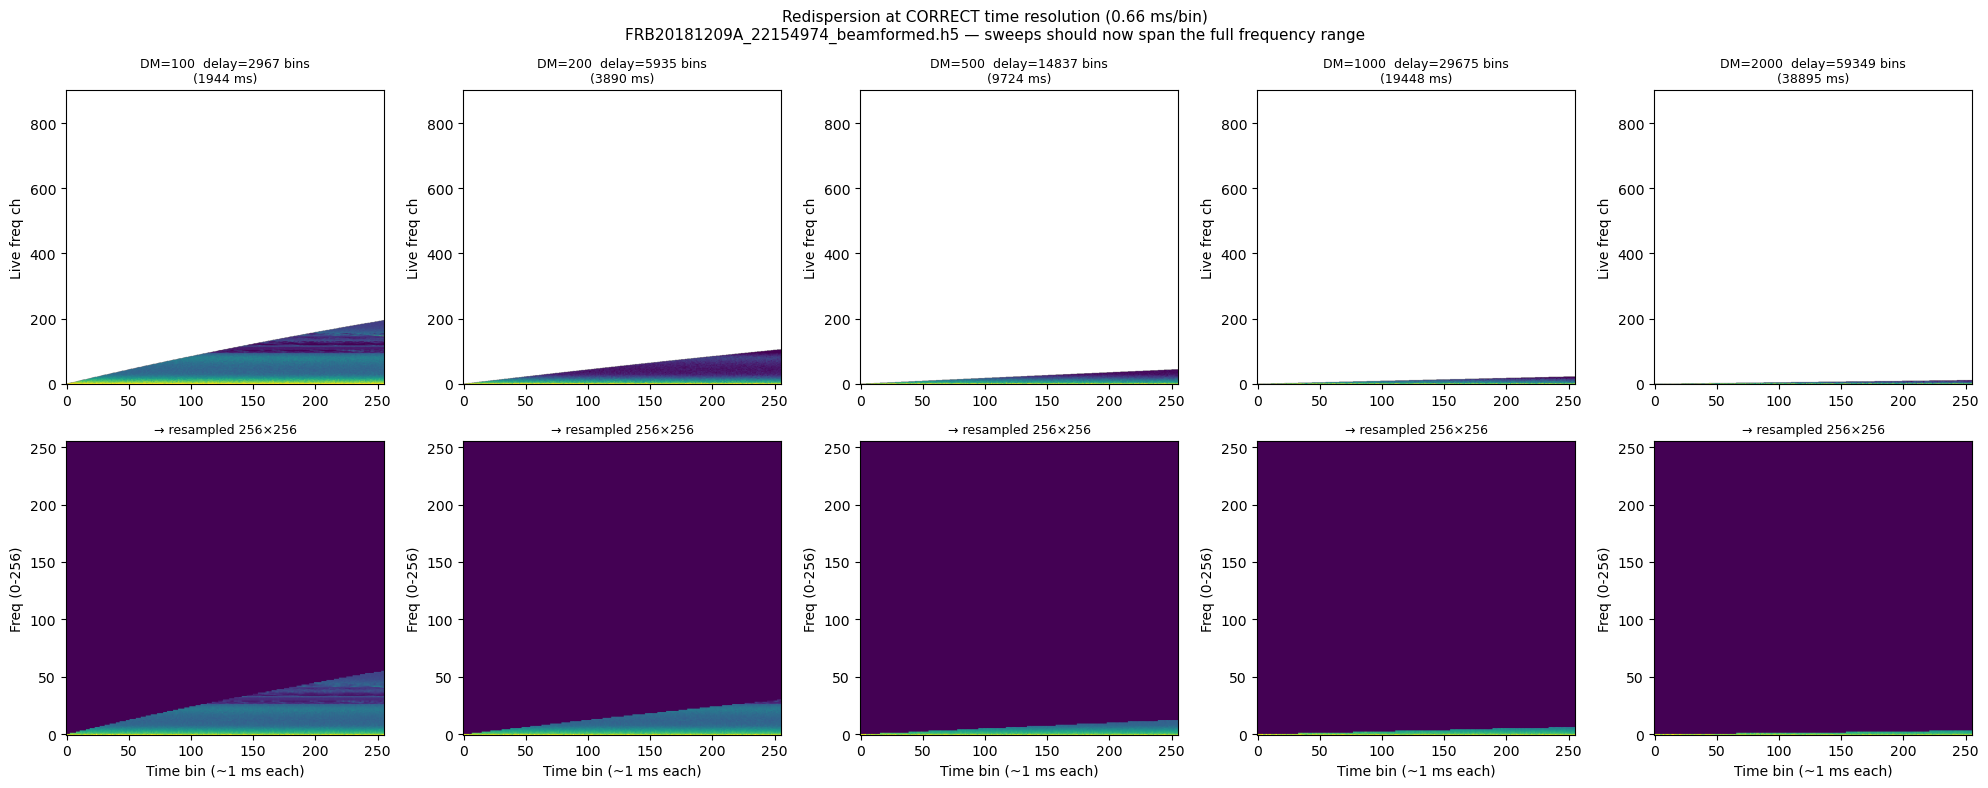


Patch covers: 256 bins × 0.655 ms = 167.8 ms
DM=100 sweep: 2967 bins — fits in patch ✅
DM=500 sweep: 14837 bins — partial sweep in patch (expected for streaming)


In [7]:
# ============================================================
# DEMO: Redispersion at correct time resolution
# ============================================================
demo_dms = [100, 200, 500, 1000, 2000]

fig, axes = plt.subplots(2, len(demo_dms), figsize=(4 * len(demo_dms), 8))

for col, dm in enumerate(demo_dms):
    delay = compute_delay_bins(dm)
    buffer_needed = PATCH_TIME_BINS + delay + 50
    
    t_lo_buf = max(0, peak - 50)
    t_hi_buf = min(demo_cropped.shape[0], t_lo_buf + buffer_needed)
    t_lo_buf = max(0, t_hi_buf - buffer_needed)
    
    region = demo_cropped[t_lo_buf:t_hi_buf, :]
    rd = redisperse(region, dm)
    
    # Find high-freq arrival
    n_top = max(1, rd.shape[1] // 10)
    top_ts = np.nanmean(rd[:, :n_top], axis=1)
    hf_arrival = np.nanargmax(np.nan_to_num(top_ts, nan=0.0))
    
    # Extract patch with burst at ~30% position
    target_pos = int(0.3 * PATCH_TIME_BINS)
    p_start = max(0, min(hf_arrival - target_pos, rd.shape[0] - PATCH_TIME_BINS))
    p_end = p_start + PATCH_TIME_BINS
    if p_end > rd.shape[0]:
        p_end = rd.shape[0]
        p_start = max(0, p_end - PATCH_TIME_BINS)
    
    patch_raw = rd[p_start:p_end, :]
    patch_rs = resample_freq(patch_raw, TARGET_FREQ_BINS)
    patch_norm = normalize_patch(np.nan_to_num(patch_rs, nan=0.0))
    
    # Top row: native freq channels
    valid_data = patch_raw[~np.isnan(patch_raw)]
    if len(valid_data) > 0:
        v1, v2 = np.percentile(valid_data, [2, 98])
    else:
        v1, v2 = 0, 1
    axes[0, col].imshow(patch_raw.T, aspect='auto', origin='lower',
                        vmin=v1, vmax=v2, cmap='viridis')
    axes[0, col].set_title(f"DM={dm}  delay={delay} bins\n({delay * EFFECTIVE_TIME_RES * 1000:.0f} ms)", fontsize=9)
    axes[0, col].set_ylabel("Live freq ch")
    
    # Bottom row: resampled to 256
    axes[1, col].imshow(patch_norm.T, aspect='auto', origin='lower', cmap='viridis')
    axes[1, col].set_title(f"→ resampled {TARGET_FREQ_BINS}×{PATCH_TIME_BINS}", fontsize=9)
    axes[1, col].set_ylabel(f"Freq (0-{TARGET_FREQ_BINS})")

for ax in axes[-1, :]:
    ax.set_xlabel("Time bin (~1 ms each)")

plt.suptitle(f"Redispersion at CORRECT time resolution ({EFFECTIVE_TIME_RES*1000:.2f} ms/bin)\n"
             f"{demo_fname} — sweeps should now span the full frequency range", fontsize=11)
plt.tight_layout()
plt.show()

print(f"\nPatch covers: {PATCH_TIME_BINS} bins × {EFFECTIVE_TIME_RES*1000:.3f} ms = "
      f"{PATCH_TIME_BINS * EFFECTIVE_TIME_RES * 1000:.1f} ms")
print(f"DM=100 sweep: {compute_delay_bins(100)} bins — fits in patch ✅")
print(f"DM=500 sweep: {compute_delay_bins(500)} bins — partial sweep in patch (expected for streaming)")

## 3. Locate Bursts

Find burst peak in downsampled + cropped data.

In [8]:
burst_info = {}

for fname, info in file_info.items():
    try:
        power_raw = load_spectrogram(info["path"], info["power_key"])
        power_ds = downsample_time(power_raw, TIME_DOWNSAMPLE)
        cropped = crop_to_live_channels(power_ds, info["live_indices"])
    except Exception as e:
        print(f"❌ {fname}: {e}")
        continue
    
    if cropped.shape[1] < 10:
        print(f"⚠️  {fname}: only {cropped.shape[1]} live channels, skipping")
        continue
    
    n_time, n_freq = cropped.shape
    ts = np.nanmean(cropped, axis=1)
    med = np.nanmedian(ts)
    mad = np.nanmedian(np.abs(ts - med))
    sigma = 1.4826 * mad
    peak_idx = np.nanargmax(ts - med)
    snr = (ts[peak_idx] - med) / sigma if sigma > 0 else 0
    burst_width = np.sum(ts > (med + 3 * sigma))
    
    burst_info[fname] = {
        "peak_idx": peak_idx,
        "snr": snr,
        "burst_width": burst_width,
        "n_time_ds": n_time,
        "n_freq_live": n_freq,
        "dm": info["dm"],
    }
    
    time_ms = n_time * EFFECTIVE_TIME_RES * 1000
    status = "✅" if snr >= MIN_BURST_SNR else "⚠️"
    print(f"{status} {fname[:50]:50s} peak={peak_idx:>4d}  SNR={snr:>6.1f}  "
          f"ds_bins={n_time:>4d} ({time_ms:.0f}ms)  live_ch={n_freq}  DM={info['dm']:.0f}")

good_files = {k: v for k, v in burst_info.items() if v["snr"] >= MIN_BURST_SNR}
print(f"\nUsable: {len(good_files)}/{len(burst_info)}")

✅ FRB20181209A_22154974_beamformed.h5                peak= 295  SNR= 167.8  ds_bins= 296 (194ms)  live_ch=903  DM=329
✅ FRB20181213A_22310619_beamformed.h5                peak= 295  SNR=  38.6  ds_bins= 296 (194ms)  live_ch=895  DM=679
✅ FRB20181226E_23948798_beamformed.h5                peak= 327  SNR=  74.8  ds_bins= 328 (215ms)  live_ch=298  DM=309
✅ FRB20181231A_24342210_beamformed.h5                peak= 239  SNR=   4.8  ds_bins= 364 (239ms)  live_ch=405  DM=1377
✅ FRB20181231C_24366209_beamformed.h5                peak= 222  SNR=  11.3  ds_bins= 224 (147ms)  live_ch=102  DM=556
✅ FRB20190102A_24510924_beamformed.h5                peak= 224  SNR=   6.6  ds_bins= 260 (170ms)  live_ch=162  DM=699
✅ FRB20190103C_24644651_beamformed.h5                peak= 397  SNR=  10.4  ds_bins= 494 (324ms)  live_ch=250  DM=1349
✅ FRB20190210B_30105124_beamformed.h5                peak= 305  SNR=  19.8  ds_bins= 313 (205ms)  live_ch=278  DM=624
✅ FRB20190213D_30502098_beamformed.h5                p

## 4. Extract Noise Patches

In [9]:
def extract_noise_patches(cropped_ds, peak_idx, burst_width,
                           patch_time=PATCH_TIME_BINS,
                           target_freq=TARGET_FREQ_BINS,
                           exclusion_factor=BURST_EXCLUSION_FACTOR):
    """Extract noise patches from downsampled+cropped data, outside burst zone."""
    n_time = cropped_ds.shape[0]
    stride = patch_time // 2
    
    pad = int(exclusion_factor * max(burst_width, 20))
    excl_start = max(0, peak_idx - pad)
    excl_end = min(n_time, peak_idx + pad)
    
    patches = []
    for t in range(0, excl_start - patch_time, stride):
        p = cropped_ds[t:t + patch_time, :]
        p_rs = resample_freq(p, target_freq)
        p_rs = np.nan_to_num(p_rs, nan=0.0)
        if patch_is_valid(p_rs):
            patches.append(normalize_patch(p_rs))
    
    for t in range(excl_end, n_time - patch_time, stride):
        p = cropped_ds[t:t + patch_time, :]
        p_rs = resample_freq(p, target_freq)
        p_rs = np.nan_to_num(p_rs, nan=0.0)
        if patch_is_valid(p_rs):
            patches.append(normalize_patch(p_rs))
    
    return patches

In [10]:
all_noise = []

for fname, bi in good_files.items():
    info = file_info[fname]
    try:
        power_raw = load_spectrogram(info["path"], info["power_key"])
        power_ds = downsample_time(power_raw, TIME_DOWNSAMPLE)
        cropped = crop_to_live_channels(power_ds, info["live_indices"])
    except Exception as e:
        print(f"❌ {fname}: {e}")
        continue
    
    patches = extract_noise_patches(cropped, bi["peak_idx"], bi["burst_width"])
    all_noise.extend(patches)
    print(f"{fname[:52]:52s}: {len(patches):>3d} noise patches")

print(f"\nTotal noise patches: {len(all_noise)}")

FRB20181209A_22154974_beamformed.h5                 :   0 noise patches
FRB20181213A_22310619_beamformed.h5                 :   0 noise patches
FRB20181226E_23948798_beamformed.h5                 :   0 noise patches
FRB20181231A_24342210_beamformed.h5                 :   0 noise patches
FRB20181231C_24366209_beamformed.h5                 :   0 noise patches
FRB20190102A_24510924_beamformed.h5                 :   0 noise patches
FRB20190103C_24644651_beamformed.h5                 :   0 noise patches
FRB20190210B_30105124_beamformed.h5                 :   0 noise patches
FRB20190213D_30502098_beamformed.h5                 :   0 noise patches
FRB20190227A_31938812_beamformed.h5                 :   1 noise patches
FRB20190304B_32415255_beamformed.h5                 :   0 noise patches
FRB20190405B_35579228_beamformed.h5                 :   0 noise patches
FRB20190420B_37342401_beamformed.h5                 :   0 noise patches
FRB20190423A_37637444_beamformed.h5                 :   0 noise 

## 5. Extract & Augment FRB Patches

In [11]:
def make_redispersed_frb_patch(cropped_ds, peak_idx, target_dm,
                                 position_frac,
                                 patch_time=PATCH_TIME_BINS,
                                 target_freq=TARGET_FREQ_BINS):
    """
    From downsampled+cropped data:
    1. Extract buffer around dedispersed pulse
    2. Redisperse at target_dm (using correct EFFECTIVE_TIME_RES)
    3. Extract patch with burst at position_frac
    4. Resample freq, normalize
    """
    n_time, n_freq = cropped_ds.shape
    delay_bins = compute_delay_bins(target_dm)
    
    buffer_needed = patch_time + delay_bins + 50
    half_buf = buffer_needed // 2
    t_lo = max(0, peak_idx - half_buf)
    t_hi = min(n_time, t_lo + buffer_needed)
    t_lo = max(0, t_hi - buffer_needed)
    
    if t_hi - t_lo < patch_time:
        return None
    
    region = cropped_ds[t_lo:t_hi, :]
    rd = redisperse(region, target_dm)
    
    # Find high-freq arrival
    n_top = max(1, n_freq // 10)
    top_ts = np.nanmean(rd[:, :n_top], axis=1)
    top_ts = np.nan_to_num(top_ts, nan=0.0)
    hf_arrival = np.argmax(top_ts)
    
    # Place burst at position_frac
    target_pos = int(position_frac * patch_time)
    p_start = hf_arrival - target_pos
    p_start = max(0, min(p_start, rd.shape[0] - patch_time))
    p_end = p_start + patch_time
    
    if p_end > rd.shape[0]:
        return None
    
    patch = rd[p_start:p_end, :]
    patch = resample_freq(patch, target_freq)
    patch = np.nan_to_num(patch, nan=0.0)
    patch = normalize_patch(patch)
    
    return patch if patch_is_valid(patch) else None

In [12]:
all_frb = []
all_frb_meta = []

temporal_positions = np.linspace(0.1, 0.9, N_TEMPORAL_SHIFTS)

for fname, bi in good_files.items():
    info = file_info[fname]
    dm_orig = bi["dm"]
    peak = bi["peak_idx"]
    count = 0
    
    try:
        power_raw = load_spectrogram(info["path"], info["power_key"])
        power_ds = downsample_time(power_raw, TIME_DOWNSAMPLE)
        cropped = crop_to_live_channels(power_ds, info["live_indices"])
    except Exception as e:
        print(f"❌ {fname}: {e}")
        continue
    
    # A) Original DM at various temporal positions
    for pos in temporal_positions:
        patch = make_redispersed_frb_patch(cropped, peak, dm_orig, pos)
        if patch is not None:
            all_frb.append(patch)
            all_frb_meta.append({"src": fname, "dm": dm_orig,
                                  "pos": pos, "type": "original"})
            count += 1
    
    # B) Augmented DMs
    aug_dms = rng.uniform(DM_AUG_RANGE[0], DM_AUG_RANGE[1], N_DM_AUGMENTS)
    for new_dm in aug_dms:
        pos = rng.uniform(0.1, 0.9)
        patch = make_redispersed_frb_patch(cropped, peak, new_dm, pos)
        if patch is not None:
            all_frb.append(patch)
            all_frb_meta.append({"src": fname, "dm": float(new_dm),
                                  "pos": pos, "type": "dm_aug"})
            count += 1
    
    print(f"{fname[:52]:52s}: {count:>3d} FRB patches")

print(f"\nTotal FRB patches: {len(all_frb)}")
n_orig = sum(1 for m in all_frb_meta if m["type"] == "original")
n_aug = sum(1 for m in all_frb_meta if m["type"] == "dm_aug")
print(f"  Original DM: {n_orig}")
print(f"  DM-augmented: {n_aug}")

FRB20181209A_22154974_beamformed.h5                 :  38 FRB patches
FRB20181213A_22310619_beamformed.h5                 :  38 FRB patches
FRB20181226E_23948798_beamformed.h5                 :  38 FRB patches
FRB20181231A_24342210_beamformed.h5                 :  38 FRB patches
FRB20181231C_24366209_beamformed.h5                 :   0 FRB patches
FRB20190102A_24510924_beamformed.h5                 :  35 FRB patches
FRB20190103C_24644651_beamformed.h5                 :  38 FRB patches
FRB20190210B_30105124_beamformed.h5                 :  38 FRB patches
FRB20190213D_30502098_beamformed.h5                 :  38 FRB patches
FRB20190227A_31938812_beamformed.h5                 :  38 FRB patches
FRB20190304B_32415255_beamformed.h5                 :  38 FRB patches
FRB20190405B_35579228_beamformed.h5                 :  38 FRB patches
FRB20190420B_37342401_beamformed.h5                 :  38 FRB patches
FRB20190423A_37637444_beamformed.h5                 :  38 FRB patches
FRB20190425B_3794819

## 6. Visualize

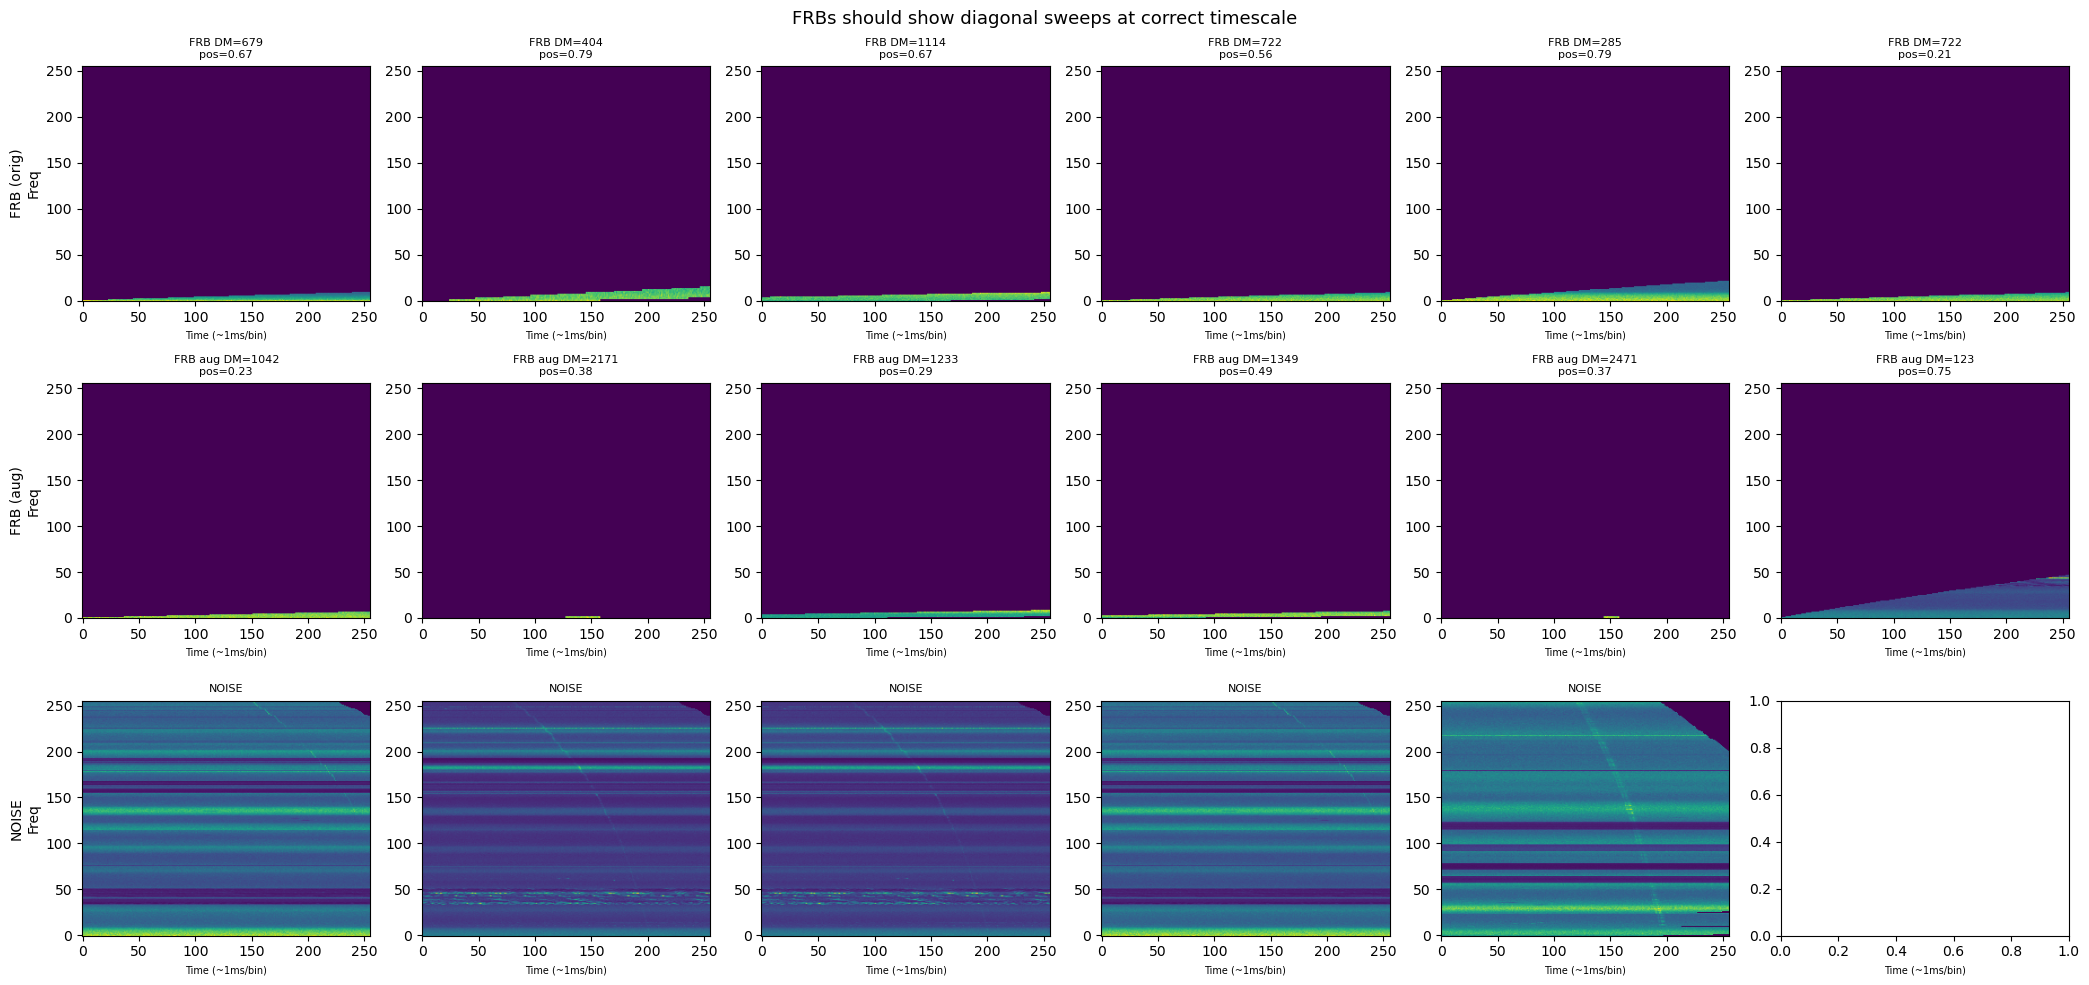

In [13]:
n_show = 6
fig, axes = plt.subplots(3, n_show, figsize=(3.5 * n_show, 10))

orig_idx = [i for i, m in enumerate(all_frb_meta) if m["type"] == "original"]
aug_idx = [i for i, m in enumerate(all_frb_meta) if m["type"] == "dm_aug"]

for col in range(min(n_show, len(orig_idx))):
    idx = orig_idx[rng.randint(len(orig_idx))]
    axes[0, col].imshow(all_frb[idx].T, aspect='auto', origin='lower', cmap='viridis')
    m = all_frb_meta[idx]
    axes[0, col].set_title(f"FRB DM={m['dm']:.0f}\npos={m['pos']:.2f}", fontsize=8)

for col in range(min(n_show, len(aug_idx))):
    idx = aug_idx[rng.randint(len(aug_idx))]
    axes[1, col].imshow(all_frb[idx].T, aspect='auto', origin='lower', cmap='viridis')
    m = all_frb_meta[idx]
    axes[1, col].set_title(f"FRB aug DM={m['dm']:.0f}\npos={m['pos']:.2f}", fontsize=8)

for col in range(min(n_show, len(all_noise))):
    idx = rng.randint(len(all_noise))
    axes[2, col].imshow(all_noise[idx].T, aspect='auto', origin='lower', cmap='viridis')
    axes[2, col].set_title("NOISE", fontsize=8)

axes[0, 0].set_ylabel("FRB (orig)\nFreq")
axes[1, 0].set_ylabel("FRB (aug)\nFreq")
axes[2, 0].set_ylabel("NOISE\nFreq")

for ax in axes.flatten():
    ax.set_xlabel("Time (~1ms/bin)", fontsize=7)

plt.suptitle("FRBs should show diagonal sweeps at correct timescale", fontsize=13)
plt.tight_layout()
plt.show()

## 7. Balance, Split & Save

In [14]:
n_frb = len(all_frb)
n_noise = len(all_noise)
print(f"Raw counts: {n_frb} FRB, {n_noise} noise")

if n_frb < n_noise * 0.5:
    print(f"FRB minority → oversampling FRB")
    noise_patches = all_noise
    frb_patches = [all_frb[i] for i in rng.choice(n_frb, n_noise, replace=True)]
elif n_noise < n_frb * 0.5:
    print(f"Noise minority → oversampling noise")
    frb_patches = all_frb
    noise_patches = [all_noise[i] for i in rng.choice(n_noise, n_frb, replace=True)]
else:
    target = min(n_frb, n_noise)
    frb_patches = [all_frb[i] for i in rng.choice(n_frb, target, replace=False)]
    noise_patches = [all_noise[i] for i in rng.choice(n_noise, target, replace=False)]

print(f"Balanced: {len(frb_patches)} FRB, {len(noise_patches)} noise")

Raw counts: 1023 FRB, 5 noise
Noise minority → oversampling noise
Balanced: 1023 FRB, 1023 noise


In [15]:
from sklearn.model_selection import train_test_split

X = np.concatenate([
    np.array(frb_patches, dtype=np.float32),
    np.array(noise_patches, dtype=np.float32)
], axis=0)
y = np.concatenate([
    np.ones(len(frb_patches), dtype=np.float32),
    np.zeros(len(noise_patches), dtype=np.float32)
])

shuf = rng.permutation(len(X))
X, y = X[shuf], y[shuf]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=SEED, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=SEED, stratify=y_temp)

print(f"Final dataset: {X.shape}")
print(f"LSTM input:    (batch, {PATCH_TIME_BINS}, {TARGET_FREQ_BINS})")
print(f"Train: {X_train.shape[0]:>5d} ({np.mean(y_train):.1%} FRB)")
print(f"Val:   {X_val.shape[0]:>5d} ({np.mean(y_val):.1%} FRB)")
print(f"Test:  {X_test.shape[0]:>5d} ({np.mean(y_test):.1%} FRB)")

Final dataset: (2046, 256, 256)
LSTM input:    (batch, 256, 256)
Train:  1432 (50.0% FRB)
Val:     307 (50.2% FRB)
Test:    307 (49.8% FRB)


In [16]:
save_path = os.path.join(OUTPUT_DIR, "lstm_dataset_v5.npz")
np.savez_compressed(
    save_path,
    X_train=X_train, y_train=y_train,
    X_val=X_val, y_val=y_val,
    X_test=X_test, y_test=y_test,
)
fsize_mb = os.path.getsize(save_path) / 1e6
print(f"Saved: {save_path} ({fsize_mb:.1f} MB)")

Saved: ./augmented_dataset/lstm_dataset_v5.npz (253.9 MB)


## 8. Final Quality Report

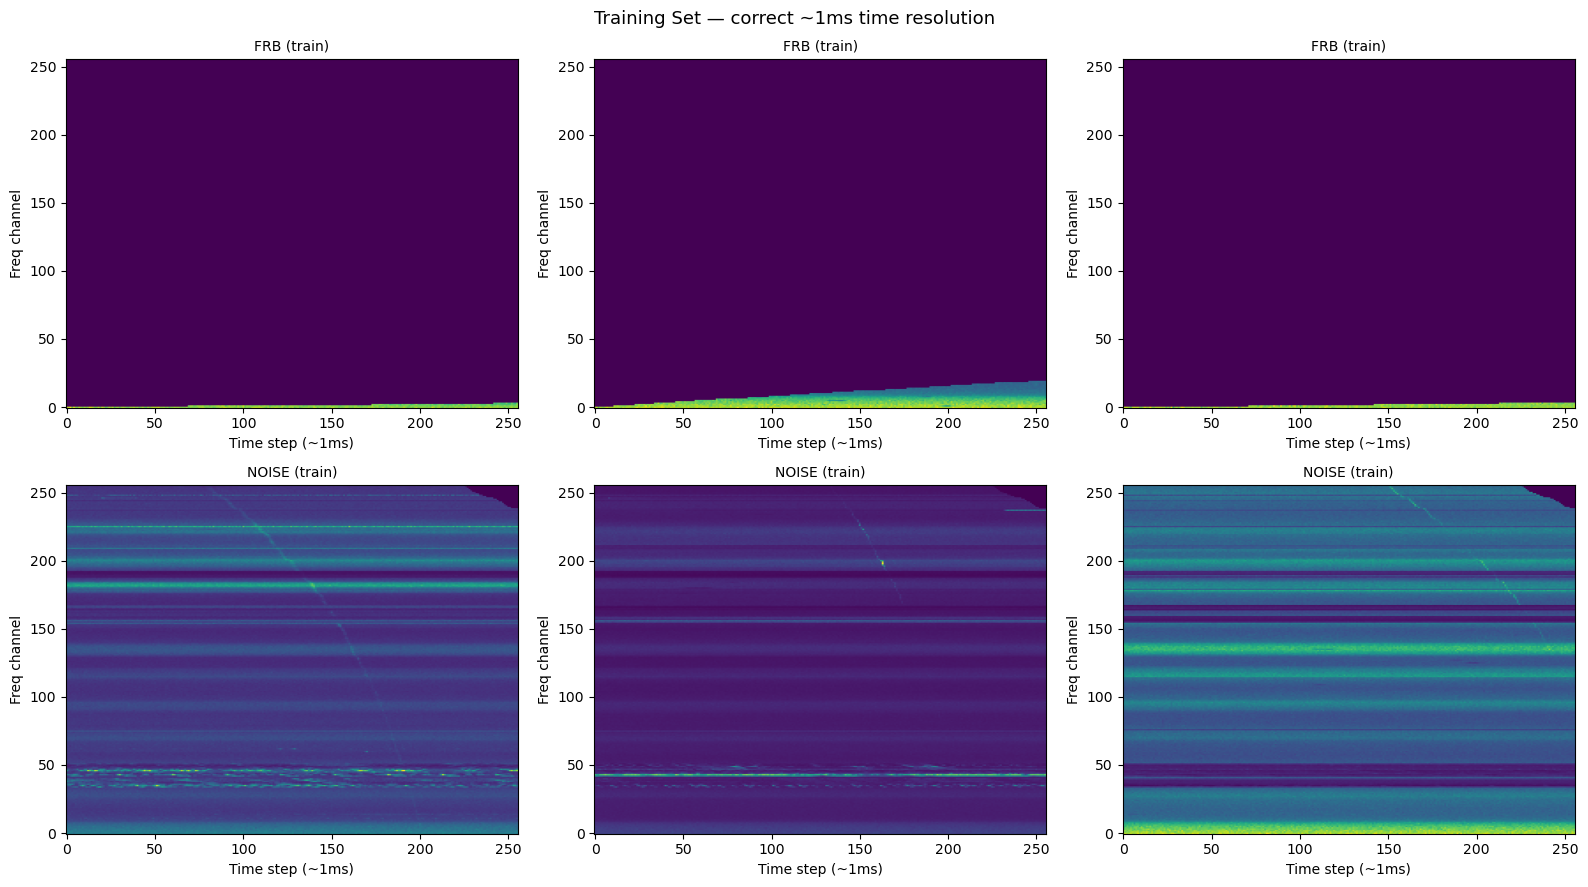

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

frb_idx = np.where(y_train == 1)[0]
noise_idx = np.where(y_train == 0)[0]

for col in range(3):
    idx = frb_idx[rng.randint(len(frb_idx))]
    axes[0, col].imshow(X_train[idx].T, aspect='auto', origin='lower', cmap='viridis')
    axes[0, col].set_title(f"FRB (train)", fontsize=10)
    axes[0, col].set_xlabel("Time step (~1ms)")
    axes[0, col].set_ylabel("Freq channel")

for col in range(3):
    idx = noise_idx[rng.randint(len(noise_idx))]
    axes[1, col].imshow(X_train[idx].T, aspect='auto', origin='lower', cmap='viridis')
    axes[1, col].set_title(f"NOISE (train)", fontsize=10)
    axes[1, col].set_xlabel("Time step (~1ms)")
    axes[1, col].set_ylabel("Freq channel")

plt.suptitle("Training Set — correct ~1ms time resolution", fontsize=13)
plt.tight_layout()
plt.show()

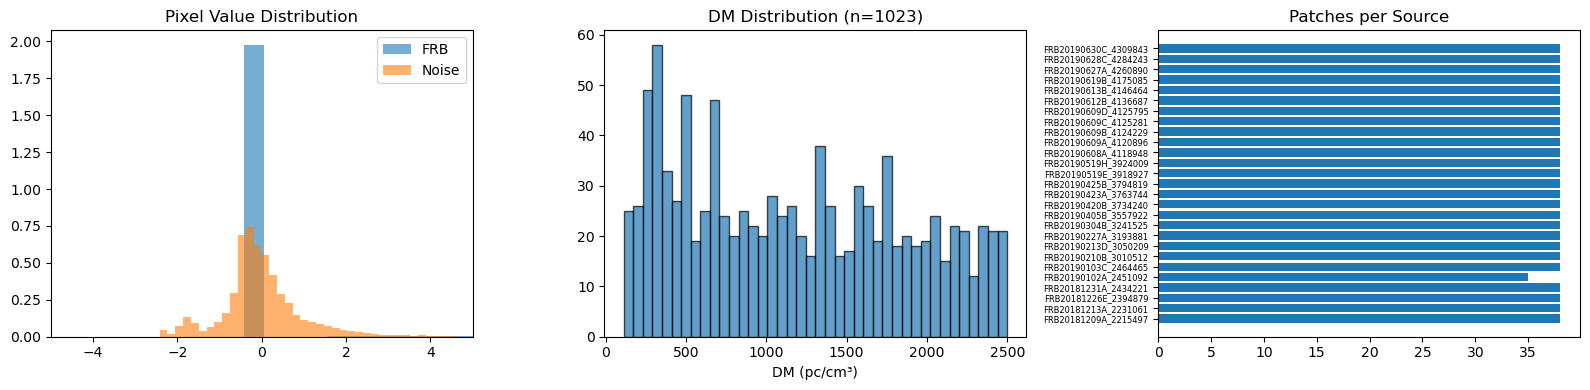


DATASET SUMMARY
Total samples:       2046
LSTM input shape:    (batch, 256, 256)
Train/Val/Test:      1432/307/307
Class balance:       50.0% FRB / 50.0% noise
Source FRBs:         29 unique bursts
DM range:            112 – 2499 pc/cm³
Live channels:       102 – 903 (mean 404)
Native time res:     2.56 μs
Downsample factor:   256
Effective time res:  0.655 ms
Patch duration:      167.8 ms
Pipeline:            Load → downsample ×256 → crop live ch → redisperse → resample freq
Saved to:            ./augmented_dataset/lstm_dataset_v5.npz

Next: LSTM training notebook


: 

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

frb_vals = X_train[y_train == 1].flatten()[::50]
noise_vals = X_train[y_train == 0].flatten()[::50]
axes[0].hist(frb_vals, bins=100, alpha=0.6, label='FRB', density=True)
axes[0].hist(noise_vals, bins=100, alpha=0.6, label='Noise', density=True)
axes[0].set_xlim(-5, 5)
axes[0].set_title("Pixel Value Distribution")
axes[0].legend()

aug_dms = [m["dm"] for m in all_frb_meta]
axes[1].hist(aug_dms, bins=40, edgecolor='black', alpha=0.7)
axes[1].set_title(f"DM Distribution (n={len(aug_dms)})")
axes[1].set_xlabel("DM (pc/cm³)")

from collections import Counter
src_counts = Counter(m["src"][:20] for m in all_frb_meta)
axes[2].barh(range(len(src_counts)), list(src_counts.values()))
axes[2].set_yticks(range(len(src_counts)))
axes[2].set_yticklabels(list(src_counts.keys()), fontsize=6)
axes[2].set_title("Patches per Source")

plt.tight_layout()
plt.show()

live_counts = [info["n_live_channels"] for info in file_info.values()]

print("\n" + "="*60)
print("DATASET SUMMARY")
print("="*60)
print(f"Total samples:       {len(X)}")
print(f"LSTM input shape:    (batch, {PATCH_TIME_BINS}, {TARGET_FREQ_BINS})")
print(f"Train/Val/Test:      {len(X_train)}/{len(X_val)}/{len(X_test)}")
print(f"Class balance:       {np.mean(y):.1%} FRB / {1-np.mean(y):.1%} noise")
print(f"Source FRBs:         {len(good_files)} unique bursts")
print(f"DM range:            {min(aug_dms):.0f} – {max(aug_dms):.0f} pc/cm³")
print(f"Live channels:       {min(live_counts)} – {max(live_counts)} (mean {np.mean(live_counts):.0f})")
print(f"Native time res:     {NATIVE_TIME_RES*1e6:.2f} μs")
print(f"Downsample factor:   {TIME_DOWNSAMPLE}")
print(f"Effective time res:  {EFFECTIVE_TIME_RES*1000:.3f} ms")
print(f"Patch duration:      {PATCH_TIME_BINS * EFFECTIVE_TIME_RES * 1000:.1f} ms")
print(f"Pipeline:            Load → downsample ×{TIME_DOWNSAMPLE} → crop live ch → redisperse → resample freq")
print(f"Saved to:            {save_path}")
print(f"\nNext: LSTM training notebook")